In [1]:
import argparse
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
all_scores = pd.read_csv('video_avCon_categories.csv')
avCont = all_scores['Average_AV'].values

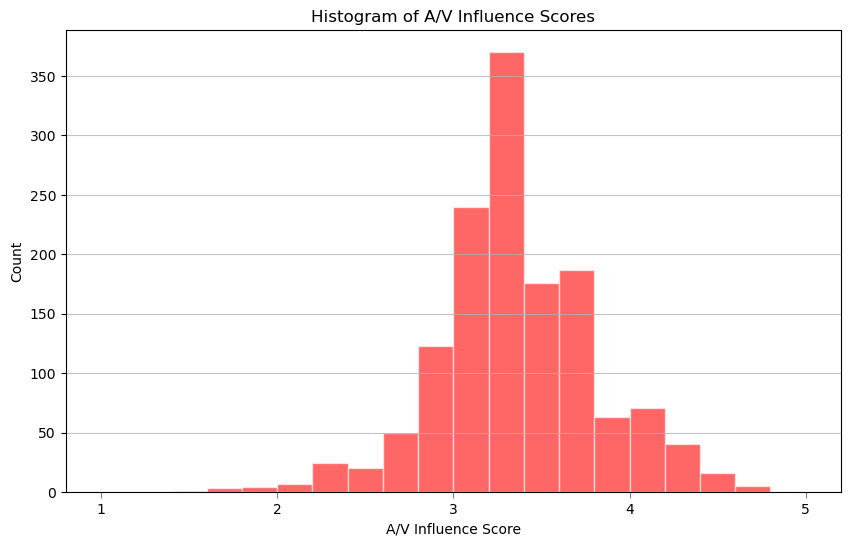

In [4]:
# Plot histogram of AV influcence scores
plt.figure(figsize=(10, 6))
plt.hist(avCont, bins=20, range=(1, 5), alpha=0.6, color='red', edgecolor='white')
# Add xticks for A/V influence scores, make them visible, have the ticks visible as minor ticks
plt.xticks(np.arange(1, 6, 1))
plt.tick_params(axis='x', which='major', length=4, bottom=True, color='gray')

plt.xlabel('A/V Influence Score')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.savefig('figures/av_influence_histogram.png', dpi=300, bbox_inches='tight')
plt.title('Histogram of A/V Influence Scores')
plt.show()

In [5]:
# Calculate the mean and standard deviation of the A/V influence scores
mean_avCont = np.mean(avCont)
std_avCont = np.std(avCont)
print(f'Mean A/V Influence Score: {mean_avCont:.2f}')
print(f'Standard Deviation of A/V Influence Score: {std_avCont:.2f}')

Mean A/V Influence Score: 3.35
Standard Deviation of A/V Influence Score: 0.45


In [37]:
# Calculate the percentage of videos with AudioOnly (A/V influence score of 1) 

# create a function to calculate the percentage of videos with each
# AV Category (1-5) in the dataset
def AVCat_percentage(category):
    # get columns "AudioOnly" of video_name contains the category
    video_cats = all_scores[all_scores['video_name'].str.contains(category)]
    AO_all = video_cats['AudioOnly'].values
    MA_all = video_cats['MostlyAudio'].values
    EQ_all = video_cats['Equally'].values
    MV_all = video_cats['MostlyVideo'].values
    VO_all = video_cats['VideoOnly'].values
    # sum each column to get the total number of videos in each category
    AO_sum = np.sum(AO_all)
    MA_sum = np.sum(MA_all)
    EQ_sum = np.sum(EQ_all)
    MV_sum = np.sum(MV_all)
    VO_sum = np.sum(VO_all)
    # get the total number of videos in the category
    total_videos = AO_sum + MA_sum + EQ_sum + MV_sum + VO_sum
    # calculate the percentage of videos in the category
    AO_p = (AO_sum / total_videos)
    MA_p = (MA_sum / total_videos)
    EQ_p = (EQ_sum / total_videos)
    MV_p = (MV_sum / total_videos)
    VO_p = (VO_sum / total_videos)
    mean_p = (AO_p*1 + MA_p*2 + EQ_p*3 + MV_p*4 + VO_p*5)
    std_p = all_scores[all_scores['video_name'].str.contains(category)]['Average_AV'].std()
    return AO_p, MA_p, EQ_p, MV_p, VO_p, mean_p, std_p # percentage of videos in category

In [40]:
AO_asmr, MA_asmr, EQ_asmr, MV_asmr, VO_asmr, mAV_asmr, stdAV_asmr = AVCat_percentage('asmr')
print(f'ASMR: AO {AO_asmr:.2%}, MA {MA_asmr:.2%}, EQ {EQ_asmr:.2%}, MV {MV_asmr:.2%}, VO {VO_asmr:.2%}')
print(f'Mean {mAV_asmr:.2f}, Std {stdAV_asmr:.2f}')


ASMR: AO 5.21%, MA 11.40%, EQ 42.57%, MV 29.80%, VO 11.02%
Mean 3.30, Std 0.47


In [41]:
AO_cats, MA_cats, EQ_cats, MV_cats, VO_cats, mAV_cats, stdAV_cats = AVCat_percentage('cats')
print(f'Cats: AO {AO_cats:.2%}, MA {MA_cats:.2%}, EQ {EQ_cats:.2%}, MV {MV_cats:.2%}, VO {VO_cats:.2%}')
print(f'Mean {mAV_cats:.2f}, Std {stdAV_cats:.2f}')


Cats: AO 2.14%, MA 9.38%, EQ 44.27%, MV 33.72%, VO 10.49%
Mean 3.41, Std 0.40


In [42]:
AO_livestream, MA_livestream, EQ_livestream, MV_livestream, VO_livestream, mAV_livestream, stdAV_livestream = AVCat_percentage('livestream')
print(f'Livestream: AO {AO_livestream:.2%}, MA {MA_livestream:.2%}, EQ {EQ_livestream:.2%}, MV {MV_livestream:.2%}, VO {VO_livestream:.2%}')
print(f'Mean {mAV_livestream:.2f}, Std {stdAV_livestream:.2f}')


Livestream: AO 3.94%, MA 13.72%, EQ 43.39%, MV 30.37%, VO 8.58%
Mean 3.26, Std 0.46


In [ ]:
AO_recipe, MA_recipe, EQ_recipe, MV_recipe, VO_recipe, mAV_recipe, stdAV_recipe = AVCat_percentage('recipe')
print(f'Recipe: AO {AO_recipe:.2%}, MA {MA_recipe:.2%}, EQ {EQ_recipe:.2%}, MV {MV_recipe:.2%}, VO {VO_recipe:.2%}')
print(f'Mean {mAV_recipe:.2f}, Std {stdAV_recipe:.2f}')

Recipe: AO 2.19%, MA 8.16%, EQ 46.11%, MV 32.33%, VO 11.21%
Mean 3.42, Std 0.42


In [44]:
AO_scenery, MA_scenery, EQ_scenery, MV_scenery, VO_scenery, mAV_scenery, stdAV_scenery = AVCat_percentage('scenery')
print(f'Scenery: AO {AO_scenery:.2%}, MA {MA_scenery:.2%}, EQ {EQ_scenery:.2%}, MV {MV_scenery:.2%}, VO {VO_scenery:.2%}')
print(f'Mean {mAV_scenery:.2f}, Std {stdAV_scenery:.2f}')

Scenery: AO 1.64%, MA 8.06%, EQ 42.76%, MV 33.30%, VO 14.25%
Mean 3.50, Std 0.38


In [ ]:
AO_speech, MA_speech, EQ_speech, MV_speech, VO_speech, mAV_speech, stdAV_speech = AVCat_percentage('speech')
print(f'Speech: AO {AO_speech:.2%}, MA {MA_speech:.2%}, EQ {EQ_speech:.2%}, MV {MV_speech:.2%}, VO {VO_speech:.2%}')
print(f'Mean {mAV_speech:.2f}, Std {stdAV_speech:.2f}')

Speech: AO 4.91%, MA 18.10%, EQ 47.56%, MV 23.49%, VO 5.94%
Mean 3.07, Std 0.47


In [46]:
AO_sport, MA_sport, EQ_sport, MV_sport, VO_sport, mAV_sport, stdAV_sport = AVCat_percentage('sport')
print(f'Sport: AO {AO_sport:.2%}, MA {MA_sport:.2%}, EQ {EQ_sport:.2%}, MV {MV_sport:.2%}, VO {VO_sport:.2%}')
print(f'Mean {mAV_sport:.2f}, Std {stdAV_sport:.2f}')


Sport: AO 2.49%, MA 9.02%, EQ 40.57%, MV 36.59%, VO 11.33%
Mean 3.45, Std 0.39


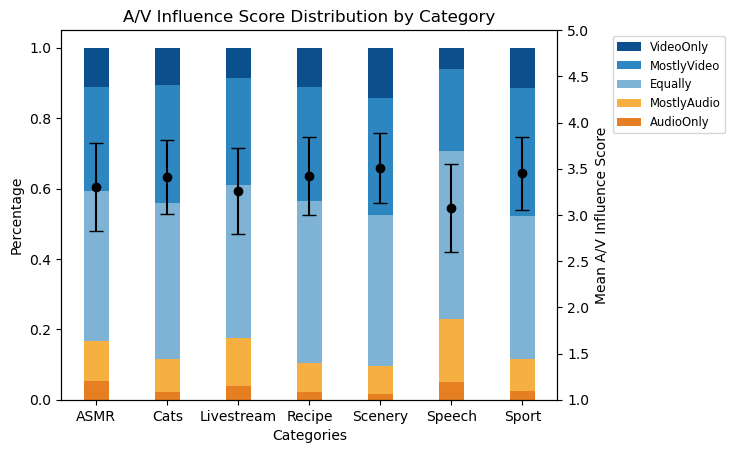

In [ ]:
# Plot the stacked bar chart of the percentage of videos in each category
categories = ['ASMR', 'Cats', 'Livestream', 'Recipe', 'Scenery', 'Speech', 'Sport']
AO_percentages = [AO_asmr, AO_cats, AO_livestream, AO_recipe, AO_scenery, AO_speech, AO_sport]
MA_percentages = [MA_asmr, MA_cats, MA_livestream, MA_recipe, MA_scenery, MA_speech, MA_sport]
EQ_percentages = [EQ_asmr, EQ_cats, EQ_livestream, EQ_recipe, EQ_scenery, EQ_speech, EQ_sport]
MV_percentages = [MV_asmr, MV_cats, MV_livestream, MV_recipe, MV_scenery, MV_speech, MV_sport]
VO_percentages = [VO_asmr, VO_cats, VO_livestream, VO_recipe, VO_scenery, VO_speech, VO_sport]

#Created a stacked bar chart with the percentages of videos in each category, with the x-axis being the categories and the y-axis being the percentage of videos in that category
AO_MA = np.array(AO_percentages) + np.array(MA_percentages)
AO_MA_EQ = AO_MA + np.array(EQ_percentages)
AO_MA_EQ_MV = AO_MA_EQ + np.array(MV_percentages)
AO_MA_EQ_MV_VO = AO_MA_EQ_MV + np.array(VO_percentages)

import matplotlib.pyplot as plt
import numpy as np

bar_width = 0.35
x = np.arange(len(categories))
#Plot all the percentages with five bars for each category, with the x-axis being the categories and the y-axis being the percentage of videos in that category
fig, ax = plt.subplots()
#Change the palette to a color from ocean blue to a color from sunset orange, with the first bar being ocean blue and the last bar being sunset orange
colors = ["#0B4F8C",  # Deep Ocean Blue
    "#2E86C1",  # Sea Blue
    "#7FB3D5",  # Soft Sky Blue
    "#F5B041",  # Golden Sunset
    "#E67E22",  # Sunset Orange
  ]
ax.bar(x, AO_MA_EQ_MV_VO, bar_width, label='VideoOnly', color=colors[0])
ax.bar(x, AO_MA_EQ_MV, bar_width, label='MostlyVideo', color=colors[1])
ax.bar(x, AO_MA_EQ, bar_width, label='Equally', color=colors[2])
ax.bar(x, AO_MA, bar_width, label='MostlyAudio', color=colors[3])
ax.bar(x, AO_percentages, bar_width, label='AudioOnly', color=colors[4])

#Lets plot the mean and standard deviation of the A/V influence scores for each category as error bars on the stacked bar chart, with the mean being a black dot and the standard deviation being a black line
#Use the right y-axis for the error bars, with the left y-axis being the percentage of videos in each category
means = [mAV_asmr, mAV_cats, mAV_livestream, mAV_recipe, mAV_scenery, mAV_speech, mAV_sport]
stds = [stdAV_asmr, stdAV_cats, stdAV_livestream, stdAV_recipe, stdAV_scenery, stdAV_speech, stdAV_sport]
# Right axis for the error bars
ax2 = ax.twinx()
# set maxmum limit for the right y-axis to 5, since the A/V influence scores are between 1 and 5
ax2.set_ylim(1, 5)
ax2.errorbar(x, means, yerr=stds, fmt='o', color='black', capsize=5)
ax2.set_ylabel('Mean A/V Influence Score')


ax.set_xlabel('Categories')
ax.set_ylabel('Percentage')

ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()


#Move the legend to outside the plot, to the right of the plot, with a smaller font size
ax.legend(loc='upper left', bbox_to_anchor=(1.1, 1), fontsize='small')


plt.savefig('figures/av_influence_category.png', dpi=300, bbox_inches='tight')
#ax.set_title('A/V Influence Score Distribution by Category')
plt.show()

For different type of distortions

In [77]:
# For each distortion

AO_c11, MA_c11, EQ_c11, MV_c11, VO_c11, mAV_c11, stdAV_c11 = AVCat_percentage('c_1_1')
print(f'c_1_1: AO {AO_c11:.2%}, MA {MA_c11:.2%}, EQ {EQ_c11:.2%}, MV {MV_c11:.2%}, VO {VO_c11:.2%}')
print(f'Mean {mAV_c11:.2f}, Std {stdAV_c11:.2f}')

c_1_1: AO 0.82%, MA 7.18%, EQ 67.46%, MV 21.17%, VO 3.36%
Mean 3.19, Std 0.22


In [78]:
AO_c12, MA_c12, EQ_c12, MV_c12, VO_c12, mAV_c12, stdAV_c12 = AVCat_percentage('c_1_2')
print(f'c_1_2: AO {AO_c12:.2%}, MA {MA_c12:.2%}, EQ {EQ_c12:.2%}, MV {MV_c12:.2%}, VO {VO_c12:.2%}')
print(f'Mean {mAV_c12:.2f}, Std {stdAV_c12:.2f}')

c_1_2: AO 7.92%, MA 17.69%, EQ 41.85%, MV 27.65%, VO 4.89%
Mean 3.04, Std 0.34


In [80]:
AO_c21, MA_c21, EQ_c21, MV_c21, VO_c21, mAV_c21, stdAV_c21 = AVCat_percentage('c_2_1')
print(f'c_2_1: AO {AO_c21:.2%}, MA {MA_c21:.2%}, EQ {EQ_c21:.2%}, MV {MV_c21:.2%}, VO {VO_c21:.2%}')
print(f'Mean {mAV_c21:.2f}, Std {stdAV_c21:.2f}')

c_2_1: AO 1.31%, MA 10.52%, EQ 48.08%, MV 32.78%, VO 7.31%
Mean 3.34, Std 0.26


In [81]:
AO_c22, MA_c22, EQ_c22, MV_c22, VO_c22, mAV_c22, stdAV_c22 = AVCat_percentage('c_2_2')
print(f'c_2_2: AO {AO_c22:.2%}, MA {MA_c22:.2%}, EQ {EQ_c22:.2%}, MV {MV_c22:.2%}, VO {VO_c22:.2%}')
print(f'Mean {mAV_c22:.2f}, Std {stdAV_c22:.2f}')

c_2_2: AO 3.85%, MA 20.23%, EQ 43.55%, MV 28.01%, VO 4.37%
Mean 3.09, Std 0.34


In [82]:
AO_c31, MA_c31, EQ_c31, MV_c31, VO_c31, mAV_c31, stdAV_c31 = AVCat_percentage('c_3_1')
print(f'c_3_1: AO {AO_c31:.2%}, MA {MA_c31:.2%}, EQ {EQ_c31:.2%}, MV {MV_c31:.2%}, VO {VO_c31:.2%}')
print(f'Mean {mAV_c31:.2f}, Std {stdAV_c31:.2f}')

AO_c32, MA_c32, EQ_c32, MV_c32, VO_c32, mAV_c32, stdAV_c32 = AVCat_percentage('c_3_2')
print(f'c_3_2: AO {AO_c32:.2%}, MA {MA_c32:.2%}, EQ {EQ_c32:.2%}, MV {MV_c32:.2%}, VO {VO_c32:.2%}')
print(f'Mean {mAV_c32:.2f}, Std {stdAV_c32:.2f}')

c_3_1: AO 1.54%, MA 7.64%, EQ 12.57%, MV 39.23%, VO 39.02%
Mean 4.07, Std 0.28
c_3_2: AO 0.91%, MA 8.31%, EQ 31.93%, MV 38.58%, VO 20.26%
Mean 3.69, Std 0.32


In [83]:
AO_asn, MA_asn, EQ_asn, MV_asn, VO_asn, mAV_asn, stdAV_asn = AVCat_percentage('asn')
print(f'asn: AO {AO_asn:.2%}, MA {MA_asn:.2%}, EQ {EQ_asn:.2%}, MV {MV_asn:.2%}, VO {VO_asn:.2%}')
print(f'Mean {mAV_asn:.2f}, Std {stdAV_asn:.2f}')

AO_stalling, MA_stalling, EQ_stalling, MV_stalling, VO_stalling, mAV_stalling, stdAV_stalling = AVCat_percentage('bf_2_7')
print(f'stalling: AO {AO_stalling:.2%}, MA {MA_stalling:.2%}, EQ {EQ_stalling:.2%}, MV {MV_stalling:.2%}, VO {VO_stalling:.2%}')
print(f'Mean {mAV_stalling:.2f}, Std {stdAV_stalling:.2f}')

asn: AO 13.33%, MA 18.85%, EQ 39.11%, MV 24.50%, VO 4.22%
Mean 2.87, Std 0.49
stalling: AO 0.59%, MA 5.88%, EQ 61.56%, MV 27.11%, VO 4.86%
Mean 3.30, Std 0.21


In [84]:
AO_qs1, MA_qs1, EQ_qs1, MV_qs1, VO_qs1, mAV_qs1, stdAV_qs1 = AVCat_percentage('qv_1')
print(f'qs_1: AO {AO_qs1:.2%}, MA {MA_qs1:.2%}, EQ {EQ_qs1:.2%}, MV {MV_qs1:.2%}, VO {VO_qs1:.2%}')
print(f'Mean {mAV_qs1:.2f}, Std {stdAV_qs1:.2f}')

AO_qs2, MA_qs2, EQ_qs2, MV_qs2, VO_qs2, mAV_qs2, stdAV_qs2 = AVCat_percentage('qv_2')
print(f'qs_2: AO {AO_qs2:.2%}, MA {MA_qs2:.2%}, EQ {EQ_qs2:.2%}, MV {MV_qs2:.2%}, VO {VO_qs2:.2%}')
print(f'Mean {mAV_qs2:.2f}, Std {stdAV_qs2:.2f}')

qs_1: AO 0.84%, MA 6.93%, EQ 45.45%, MV 38.37%, VO 8.41%
Mean 3.47, Std 0.29
qs_2: AO 1.08%, MA 7.96%, EQ 47.33%, MV 36.30%, VO 7.33%
Mean 3.41, Std 0.27


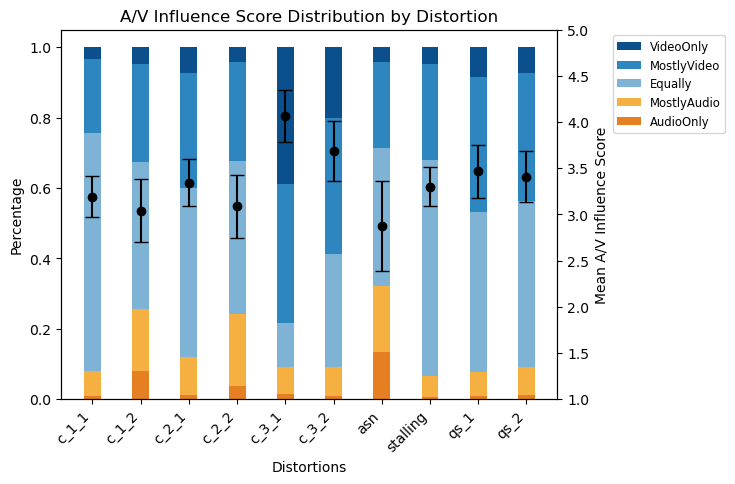

In [89]:
# Plot the stacked bar chart of the percentage of videos in each distortion 
distortions = ['c_1_1', 'c_1_2', 'c_2_1', 'c_2_2', 'c_3_1', 'c_3_2', 'asn', 'stalling', 'qs_1', 'qs_2']
AO_percentages_dist = [AO_c11, AO_c12, AO_c21, AO_c22, AO_c31, AO_c32, AO_asn, AO_stalling, AO_qs1, AO_qs2]
MA_percentages_dist = [MA_c11, MA_c12, MA_c21, MA_c22, MA_c31, MA_c32, MA_asn, MA_stalling, MA_qs1, MA_qs2]
EQ_percentages_dist = [EQ_c11, EQ_c12, EQ_c21, EQ_c22, EQ_c31, EQ_c32, EQ_asn, EQ_stalling, EQ_qs1, EQ_qs2]
MV_percentages_dist = [MV_c11, MV_c12, MV_c21, MV_c22, MV_c31, MV_c32, MV_asn, MV_stalling, MV_qs1, MV_qs2]
VO_percentages_dist = [VO_c11, VO_c12, VO_c21, VO_c22, VO_c31, VO_c32, VO_asn, VO_stalling, VO_qs1, VO_qs2]

# Created a stacked bar chart with the percentages of videos in each distortion, with the x-axis being the distortions and the y-axis being the percentage of videos in that distortion
AO_MA_dist = np.array(AO_percentages_dist) + np.array(MA_percentages_dist)
AO_MA_EQ_dist = AO_MA_dist + np.array(EQ_percentages_dist)
AO_MA_EQ_MV_dist = AO_MA_EQ_dist + np.array(MV_percentages_dist)
AO_MA_EQ_MV_VO_dist = AO_MA_EQ_MV_dist + np.array(VO_percentages_dist)

#Lets plot the mean and standard deviation of the A/V influence scores for each distortion as error bars on the stacked bar chart, with the mean being a black dot and the standard deviation being a black line
means_dist = [mAV_c11, mAV_c12, mAV_c21, mAV_c22, mAV_c31, mAV_c32, mAV_asn, mAV_stalling, mAV_qs1, mAV_qs2]
stds_dist = [stdAV_c11, stdAV_c12, stdAV_c21, stdAV_c22, stdAV_c31, stdAV_c32, stdAV_asn, stdAV_stalling, stdAV_qs1, stdAV_qs2]


# Plot the stacked bar chart of the percentage of videos in each distortion
bar_width = 0.35
x_dist = np.arange(len(distortions))
fig, ax = plt.subplots()
ax.bar(x_dist, AO_MA_EQ_MV_VO_dist, bar_width, label='VideoOnly', color=colors[0])
ax.bar(x_dist, AO_MA_EQ_MV_dist, bar_width, label='MostlyVideo', color=colors[1])
ax.bar(x_dist, AO_MA_EQ_dist, bar_width, label='Equally', color=colors[2])
ax.bar(x_dist, AO_MA_dist, bar_width, label='MostlyAudio', color=colors[3])
ax.bar(x_dist, AO_percentages_dist, bar_width, label='AudioOnly', color=colors[4])
# Legend
ax.set_xlabel('Distortions')
ax.set_ylabel('Percentage')
# Set the x-ticks to be the distortions
ax.set_xticks(x_dist)
ax.set_xticklabels(distortions, rotation=45, ha='right')

# Right axis for the error bars
ax2 = ax.twinx()
# set maxmum limit for the right y-axis to 5, since the A/V influence scores are between 1 and 5
ax2.set_ylim(1, 5)
ax2.errorbar(x_dist, means_dist, yerr=stds_dist, fmt='o', color='black', capsize=5)
ax2.set_ylabel('Mean A/V Influence Score')

# Move the legend to outside the plot, to the right of the plot, with a smaller font size
ax.legend(loc='upper left', bbox_to_anchor=(1.1, 1), fontsize='small')


plt.savefig('figures/av_influence_distortion.png', dpi=300, bbox_inches='tight')

ax.set_title('A/V Influence Score Distribution by Distortion')
# Show the plot
plt.show()